<a href="https://colab.research.google.com/github/juzt-me/Insurance_Claims_Analysis/blob/main/Insurance_Claims_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import zipfile
import os

zip_path = "/content/insurance_claims_insight_dataset.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/insurance_data")

data_folder = "/content/insurance_data/insurance_claims_insight_dataset"

print(os.listdir(data_folder))

['claims.csv', 'customers.csv', 'incidents.csv', 'policies.csv', 'README.txt', 'processing.csv']


In [3]:

import pandas as pd
import os

data_folder = "/content/insurance_data/insurance_claims_insight_dataset"

claims = pd.read_csv(os.path.join(data_folder, "claims.csv"))
policies = pd.read_csv(os.path.join(data_folder, "policies.csv"))
customers = pd.read_csv(os.path.join(data_folder, "customers.csv"))
incidents = pd.read_csv(os.path.join(data_folder, "incidents.csv"))
processing = pd.read_csv(os.path.join(data_folder, "processing.csv"))

print("Claims:", claims.shape)
print("Policies:", policies.shape)
print("Customers:", customers.shape)
print("Incidents:", incidents.shape)
print("Processing:", processing.shape)

display(claims.head())


Claims: (600, 8)
Policies: (600, 4)
Customers: (600, 3)
Incidents: (600, 4)
Processing: (600, 5)


,claim_number,customer_id,policy_id,incident_id,claim_date,claim_type,claim_amount,claim_status
0,CLM100001,CUST2001,POL3001,INC4001,2025-08-15,Property,3928.53,Pending
1,CLM100002,CUST2002,POL3002,INC4002,2025-10-30,motor,3084.27,Under Investigation
2,CLM100003,CUST2003,POL3003,INC4003,2025-08-22,Travel,3651.67,Pending
3,CLM100004,CUST2004,POL3004,INC4004,2025-08-05,motor,9717.59,Under Investigation
4,CLM100005,CUST2005,POL3005,INC4005,2025-06-20,Travel,2059.95,Under Investigation


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

claims = pd.read_csv(f"{data_folder}/claims.csv")
policies = pd.read_csv(f"{data_folder}/policies.csv")
customers = pd.read_csv(f"{data_folder}/customers.csv")
incidents = pd.read_csv(f"{data_folder}/incidents.csv")
processing = pd.read_csv(f"{data_folder}/processing.csv")

datasets = {
    "Claims": claims,
    "Policies": policies,
    "Customers": customers,
    "Incidents": incidents,
    "Processing": processing
}

for name, data in datasets.items():
    print(f"\n{name}: {data.shape[0]} rows, {data.shape[1]} columns")
    display(data.head(3))



Claims: 600 rows, 8 columns


,claim_number,customer_id,policy_id,incident_id,claim_date,claim_type,claim_amount,claim_status
0,CLM100001,CUST2001,POL3001,INC4001,2025-08-15,Property,3928.53,Pending
1,CLM100002,CUST2002,POL3002,INC4002,2025-10-30,motor,3084.27,Under Investigation
2,CLM100003,CUST2003,POL3003,INC4003,2025-08-22,Travel,3651.67,Pending



Policies: 600 rows, 4 columns


,policy_id,policy_type,premium,policy_tenure_years
0,POL3001,Comprehensive,30672.37,4
1,POL3002,Property Cover,13745.03,9
2,POL3003,Comprehensive,32495.66,7



Customers: 600 rows, 3 columns


,customer_id,region,customer_tenure_years
0,CUST2001,Central,15
1,CUST2002,East,9
2,CUST2003,south,5



Incidents: 600 rows, 4 columns


,incident_id,incident_type,location,severity
0,INC4001,Fire,Madurai,High
1,INC4002,Fire,Bengaluru,High
2,INC4003,Accidental Damage,Tiruchirappalli,Low



Processing: 600 rows, 5 columns


,claim_number,assignee,process_stage,settlement_days,investigation_required
0,CLM100001,C. Raj,Investigation,17.0,Yes
1,CLM100002,E. Anand,Investigation,14.0,Yes
2,CLM100003,B. Devi,Investigation,15.0,Yes


In [5]:

for name, data in datasets.items():
    print("\n", "=" * 50)
    print("DATASET:", name)
    print("\nData types:")
    print(data.dtypes)
    print("\nMissing values:")
    print(data.isnull().sum())
    print("\nDuplicate rows:", data.duplicated().sum())

print("\nClaim status distribution:")
print(claims["claim_status"].value_counts(dropna=False))



DATASET: Claims

Data types:
claim_number     object
customer_id      object
policy_id        object
incident_id      object
claim_date       object
claim_type       object
claim_amount    float64
claim_status     object
dtype: object

Missing values:
claim_number    0
customer_id     0
policy_id       0
incident_id     0
claim_date      0
claim_type      0
claim_amount    1
claim_status    0
dtype: int64

Duplicate rows: 0

DATASET: Policies

Data types:
policy_id               object
policy_type             object
premium                float64
policy_tenure_years      int64
dtype: object

Missing values:
policy_id              0
policy_type            0
premium                1
policy_tenure_years    0
dtype: int64

Duplicate rows: 0

DATASET: Customers

Data types:
customer_id              object
region                   object
customer_tenure_years     int64
dtype: object

Missing values:
customer_id              0
region                   1
customer_tenure_years    0
dtype: int6

In [6]:

print("Duplicate claim numbers:")
print(claims[claims["claim_number"].duplicated(keep=False)])

print("\nClaim type variations:")
print(claims["claim_type"].value_counts(dropna=False))

print("\nClaim amount statistics:")
print(claims["claim_amount"].describe())

print("\nNon-positive claim amounts:")
print(claims[claims["claim_amount"] <= 0])

print("\nInvalid settlement durations:")
print(processing[processing["settlement_days"] <= 0])

print("\nMissing incident details:")
print(incidents[incidents["incident_type"].isna()])


Duplicate claim numbers:
   claim_number customer_id policy_id incident_id  claim_date claim_type  \
54    CLM100055    CUST2055   POL3055     INC4055  2025-11-07   PROPERTY   
55    CLM100055    CUST2056   POL3056     INC4056  2025-11-10      Motor   

    claim_amount claim_status  
54       7090.43      Pending  
55      14153.49      Settled  

Claim type variations:
claim_type
Motor       216
Property    125
Travel       77
motor        67
Health       65
PROPERTY     49
MOTOR         1
Name: count, dtype: int64

Claim amount statistics:
count       599.000000
mean       7193.018164
std       12917.517883
min       -2500.000000
25%        2903.310000
50%        4904.410000
75%        7966.245000
max      269944.350000
Name: claim_amount, dtype: float64

Non-positive claim amounts:
   claim_number customer_id policy_id incident_id  claim_date claim_type  \
42    CLM100043    CUST2043   POL3043     INC4043  2025-05-08      Motor   

    claim_amount claim_status  
42       -2500.0  

In [7]:

# Work on copies of the original datasets
claims = claims.copy()
policies = policies.copy()
customers = customers.copy()
incidents = incidents.copy()
processing = processing.copy()

# Standardise text categories
text_columns = [
    (claims, ["claim_type", "claim_status"]),
    (policies, ["policy_type"]),
    (customers, ["region"]),
    (incidents, ["incident_type", "severity"]),
    (processing, ["assignee", "process_stage",
                  "investigation_required"])
]

for data, columns in text_columns:
    for column in columns:
        data[column] = (
            data[column].astype("string").str.strip().str.title()
        )

# Convert data types
claims["claim_date"] = pd.to_datetime(
    claims["claim_date"], errors="coerce"
)

for column in ["claim_amount"]:
    claims[column] = pd.to_numeric(
        claims[column], errors="coerce"
    )

for column in ["premium", "policy_tenure_years"]:
    policies[column] = pd.to_numeric(
        policies[column], errors="coerce"
    )

customers["customer_tenure_years"] = pd.to_numeric(
    customers["customer_tenure_years"], errors="coerce"
)

processing["settlement_days"] = pd.to_numeric(
    processing["settlement_days"], errors="coerce"
)

# Remove duplicate claim numbers
claims = claims.drop_duplicates(
    subset="claim_number", keep="first"
).copy()

# Replace invalid amounts and durations with missing values
claims.loc[claims["claim_amount"] <= 0, "claim_amount"] = np.nan
processing.loc[
    processing["settlement_days"] <= 0,
    "settlement_days"
] = np.nan

# Flag claim value outliers using the IQR method
q1 = claims["claim_amount"].quantile(0.25)
q3 = claims["claim_amount"].quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

claims["extreme_claim_value"] = (
    (claims["claim_amount"] < lower_limit) |
    (claims["claim_amount"] > upper_limit)
)

# Report outlier count before filling missing amounts
print("Flagged claim value outliers:",
      int(claims["extreme_claim_value"].sum()))

# Fill missing numeric values using medians
claims["claim_amount"] = claims["claim_amount"].fillna(
    claims["claim_amount"].median()
)

policies["premium"] = policies["premium"].fillna(
    policies["premium"].median()
)

processing["settlement_days"] = (
    processing["settlement_days"].fillna(
        processing["settlement_days"].median()
    )
)

# Fill missing categorical information transparently
for data, columns in [
    (policies, ["policy_type"]),
    (customers, ["region"]),
    (incidents, ["incident_type", "severity"]),
    (processing, ["assignee", "process_stage",
                  "investigation_required"])
]:
    for column in columns:
        data[column] = data[column].fillna("Unknown")

print("Cleaning completed.")
print("Remaining missing claim values:")
print(claims.isnull().sum())


Flagged claim value outliers: 47
Cleaning completed.
Remaining missing claim values:
claim_number           0
customer_id            0
policy_id              0
incident_id            0
claim_date             0
claim_type             0
claim_amount           0
claim_status           0
extreme_claim_value    0
dtype: int64


In [8]:

df = claims.merge(
    policies, on="policy_id", how="left",
    validate="many_to_one"
)

df = df.merge(
    customers, on="customer_id", how="left",
    validate="many_to_one"
)

df = df.merge(
    incidents, on="incident_id", how="left",
    validate="many_to_one"
)

df = df.merge(
    processing, on="claim_number", how="left",
    validate="one_to_one"
)

print("Combined dataset shape:", df.shape)
print("Unique claims:", df["claim_number"].nunique())
display(df.head())


Combined dataset shape: (599, 21)
Unique claims: 599


,claim_number,customer_id,policy_id,incident_id,claim_date,claim_type,claim_amount,claim_status,extreme_claim_value,policy_type,...,policy_tenure_years,region,customer_tenure_years,incident_type,location,severity,assignee,process_stage,settlement_days,investigation_required
0,CLM100001,CUST2001,POL3001,INC4001,2025-08-15,Property,3928.53,Pending,False,Comprehensive,...,4,Central,15,Fire,Madurai,High,C. Raj,Investigation,17.0,Yes
1,CLM100002,CUST2002,POL3002,INC4002,2025-10-30,Motor,3084.27,Under Investigation,False,Property Cover,...,9,East,9,Fire,Bengaluru,High,E. Anand,Investigation,14.0,Yes
2,CLM100003,CUST2003,POL3003,INC4003,2025-08-22,Travel,3651.67,Pending,False,Comprehensive,...,7,South,5,Accidental Damage,Tiruchirappalli,Low,B. Devi,Investigation,15.0,Yes
3,CLM100004,CUST2004,POL3004,INC4004,2025-08-05,Motor,9717.59,Under Investigation,False,Premium Plus,...,15,West,9,Accidental Damage,Hyderabad,High,A. Kumar,Investigation,9.0,Yes
4,CLM100005,CUST2005,POL3005,INC4005,2025-06-20,Travel,2059.95,Under Investigation,False,Property Cover,...,12,North,13,Collision,Madurai,High,B. Devi,Assessment,13.0,No


In [9]:

# Time-based features
df["claim_month"] = df["claim_date"].dt.month_name()
df["claim_year"] = df["claim_date"].dt.year

# Compare claim amount with policy premium
df["claim_to_premium_ratio"] = (
    df["claim_amount"] / df["premium"].replace(0, np.nan)
)

# Categorise claim values
value_threshold = df["claim_amount"].quantile(0.75)

df["claim_value_category"] = np.where(
    df["claim_amount"] >= value_threshold,
    "High Value",
    "Regular Value"
)

# Settlement duration category
median_days = df["settlement_days"].median()

df["settlement_category"] = np.where(
    df["settlement_days"] > median_days,
    "Long Settlement",
    "Normal Settlement"
)

# Investigation priority indicator
df["investigation_priority"] = np.where(
    df["severity"].isin(["High", "Critical"]) |
    df["investigation_required"].eq("Yes"),
    "Review",
    "Standard"
)

display(df[
    ["claim_number", "claim_amount", "severity",
     "settlement_days", "claim_value_category",
     "settlement_category", "investigation_priority"]
].head(10))


,claim_number,claim_amount,severity,settlement_days,claim_value_category,settlement_category,investigation_priority
0,CLM100001,3928.53,High,17.0,Regular Value,Normal Settlement,Review
1,CLM100002,3084.27,High,14.0,Regular Value,Normal Settlement,Review
2,CLM100003,3651.67,Low,15.0,Regular Value,Normal Settlement,Review
3,CLM100004,9717.59,High,9.0,High Value,Normal Settlement,Review
4,CLM100005,2059.95,High,13.0,Regular Value,Normal Settlement,Review
5,CLM100006,4373.62,High,28.0,Regular Value,Long Settlement,Review
6,CLM100007,11877.52,Low,3.0,High Value,Normal Settlement,Standard
7,CLM100008,1708.78,Medium,12.0,Regular Value,Normal Settlement,Standard
8,CLM100009,7349.01,Medium,9.0,Regular Value,Normal Settlement,Standard
9,CLM100010,2660.99,Low,8.0,Regular Value,Normal Settlement,Standard


In [10]:

print("NUMERICAL SUMMARY")
display(df[[
    "claim_amount", "premium",
    "settlement_days", "policy_tenure_years",
    "customer_tenure_years"
]].describe().round(2))

print("CLAIM STATUS SUMMARY")
display(df["claim_status"].value_counts().to_frame("Claim Count"))

print("CLAIM TYPE SUMMARY")
claim_type_summary = df.groupby("claim_type").agg(
    claim_count=("claim_number", "nunique"),
    total_claim_value=("claim_amount", "sum"),
    average_claim_value=("claim_amount", "mean"),
    average_settlement_days=("settlement_days", "mean")
).round(2)

display(claim_type_summary)

print("REGIONAL SUMMARY")
display(
    df.groupby("region").agg(
        claim_count=("claim_number", "nunique"),
        total_claim_value=("claim_amount", "sum"),
        average_claim_value=("claim_amount", "mean")
    ).round(2).sort_values("claim_count", ascending=False)
)


NUMERICAL SUMMARY


,claim_amount,premium,settlement_days,policy_tenure_years,customer_tenure_years
count,599.00,599.00,599.00,599.00,599.00
mean,7189.94,18131.66,24.21,7.98,10.12
std,12908.98,9346.21,66.85,4.24,5.83
min,486.83,2572.64,1.00,1.00,0.00
25%,2916.76,9679.71,10.00,4.00,5.00
50%,4904.41,18076.38,17.00,8.00,10.00
75%,7954.78,26178.61,24.00,12.00,15.00
max,269944.35,34943.32,999.00,15.00,20.00


CLAIM STATUS SUMMARY


,Claim Count
claim_status,
Settled,327
Pending,131
Under Investigation,91
Rejected,50


CLAIM TYPE SUMMARY


,claim_count,total_claim_value,average_claim_value,average_settlement_days
claim_type,,,,
Health,65,404858.63,6228.59,25.12
Motor,283,2144985.02,7579.45,26.72
Property,174,1178521.58,6773.11,17.86
Travel,77,578407.98,7511.79,28.55


REGIONAL SUMMARY


,claim_count,total_claim_value,average_claim_value
region,,,
South,172,1331697.22,7742.43
North,168,1179962.29,7023.59
West,113,725134.50,6417.12
East,74,466553.31,6304.77
Central,71,598780.25,8433.52
Unknown,1,4645.64,4645.64


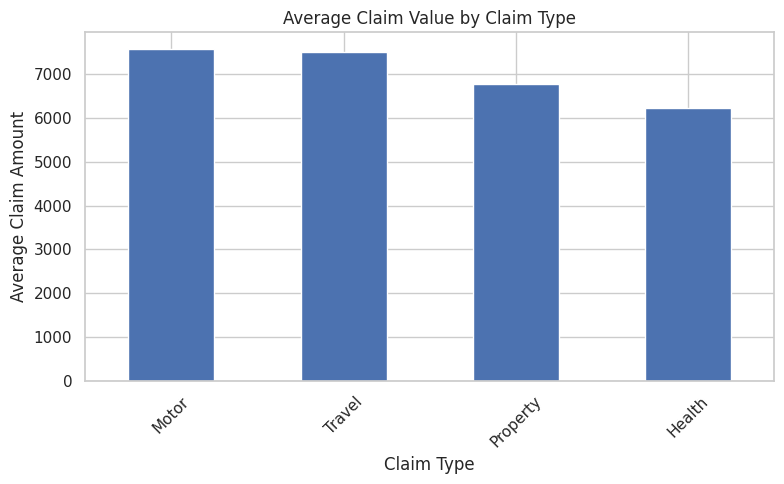

In [11]:

summary = df.groupby("claim_type")["claim_amount"].mean().sort_values(
    ascending=False
)

summary.plot(kind="bar", figsize=(8, 5))
plt.title("Average Claim Value by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Average Claim Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


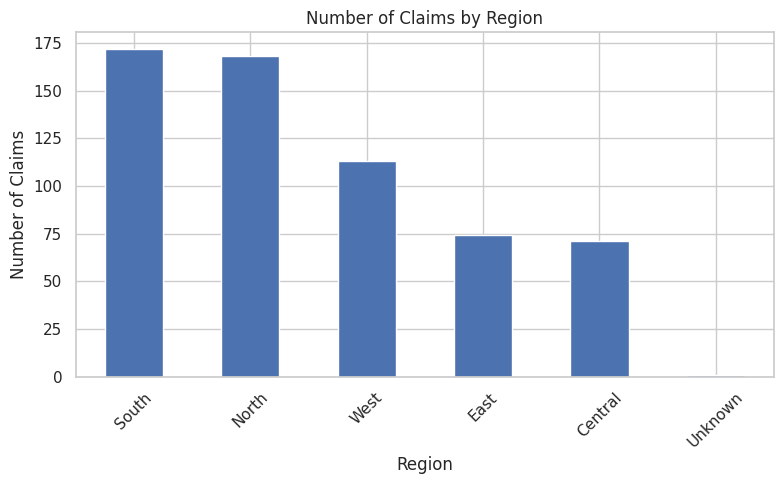

In [12]:

region_counts = df["region"].value_counts()

region_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Number of Claims by Region")
plt.xlabel("Region")
plt.ylabel("Number of Claims")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


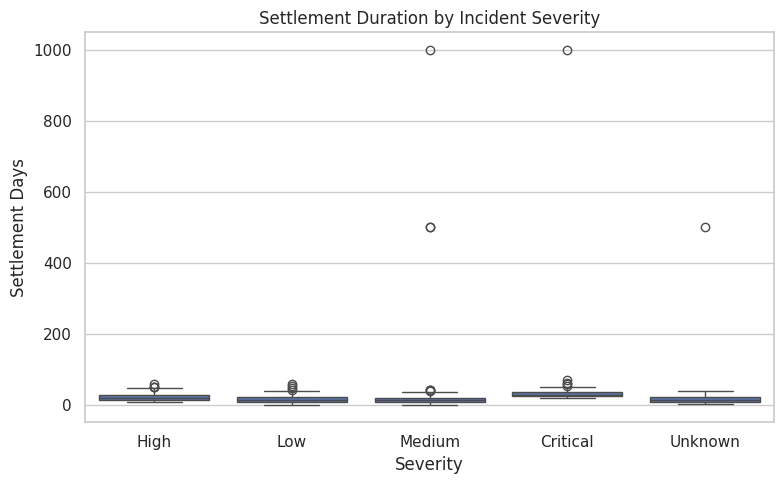

In [13]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="severity", y="settlement_days")
plt.title("Settlement Duration by Incident Severity")
plt.xlabel("Severity")
plt.ylabel("Settlement Days")
plt.tight_layout()
plt.show()


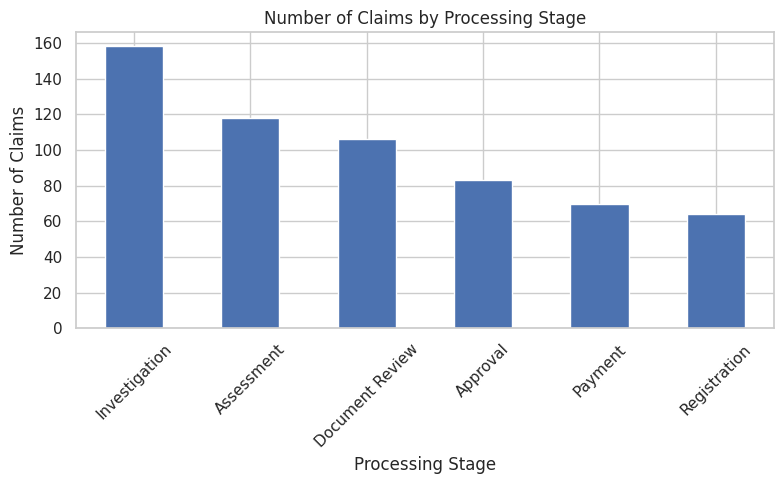

In [14]:

stage_counts = df["process_stage"].value_counts()

stage_counts.plot(kind="bar", figsize=(8, 5))
plt.title("Number of Claims by Processing Stage")
plt.xlabel("Processing Stage")
plt.ylabel("Number of Claims")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


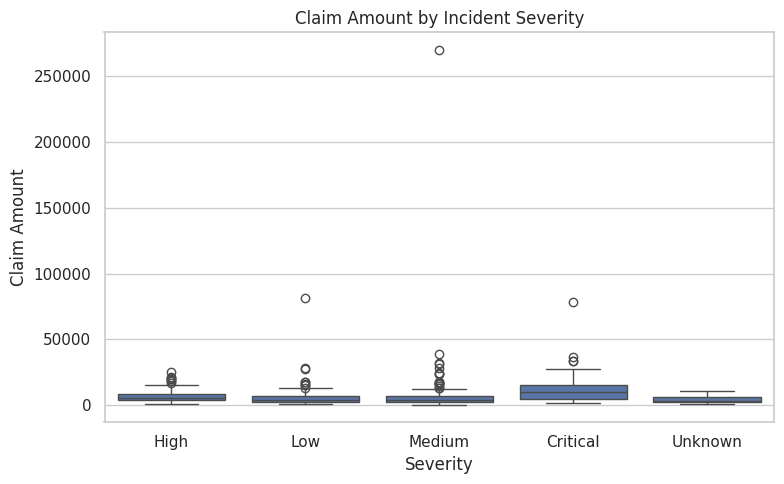

In [15]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="severity", y="claim_amount")
plt.title("Claim Amount by Incident Severity")
plt.xlabel("Severity")
plt.ylabel("Claim Amount")
plt.tight_layout()
plt.show()


,assigned_claims,average_settlement_days,average_claim_amount
assignee,,,
A. Kumar,127,26.64,6926.65
B. Devi,127,24.47,9036.24
D. Priya,122,18.70,7094.49
E. Anand,112,27.81,6155.49
C. Raj,111,23.54,6527.42


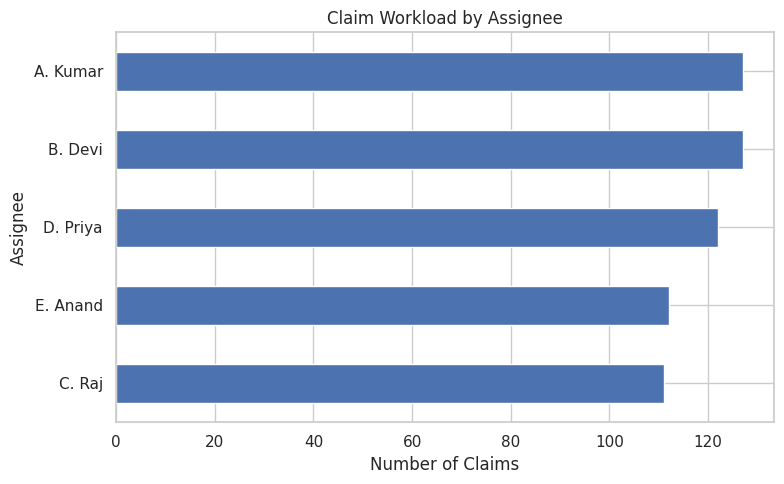

In [16]:

workload = df.groupby("assignee").agg(
    assigned_claims=("claim_number", "nunique"),
    average_settlement_days=("settlement_days", "mean"),
    average_claim_amount=("claim_amount", "mean")
).round(2)

display(workload.sort_values("assigned_claims", ascending=False))

workload["assigned_claims"].sort_values().plot(
    kind="barh", figsize=(8, 5)
)
plt.title("Claim Workload by Assignee")
plt.xlabel("Number of Claims")
plt.ylabel("Assignee")
plt.tight_layout()
plt.show()


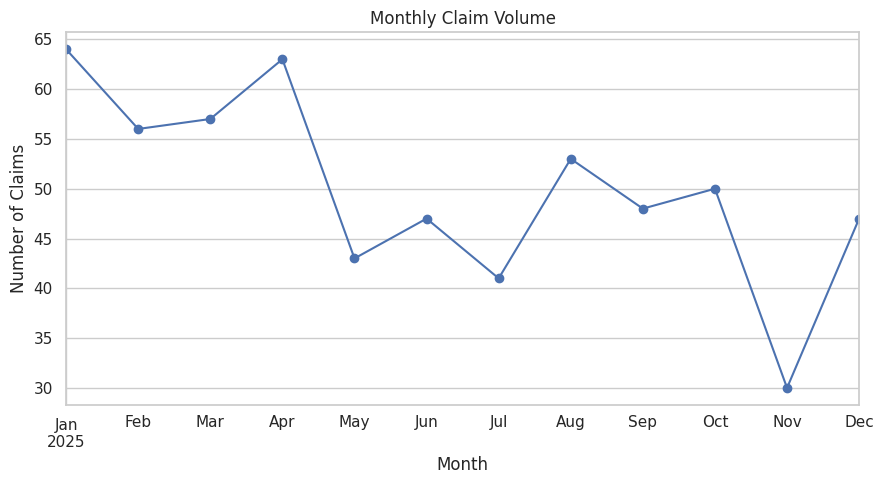

In [17]:

monthly = (
    df.dropna(subset=["claim_date"])
      .set_index("claim_date")
      .resample("ME")["claim_number"]
      .nunique()
)

monthly.plot(kind="line", marker="o", figsize=(9, 5))
plt.title("Monthly Claim Volume")
plt.xlabel("Month")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()


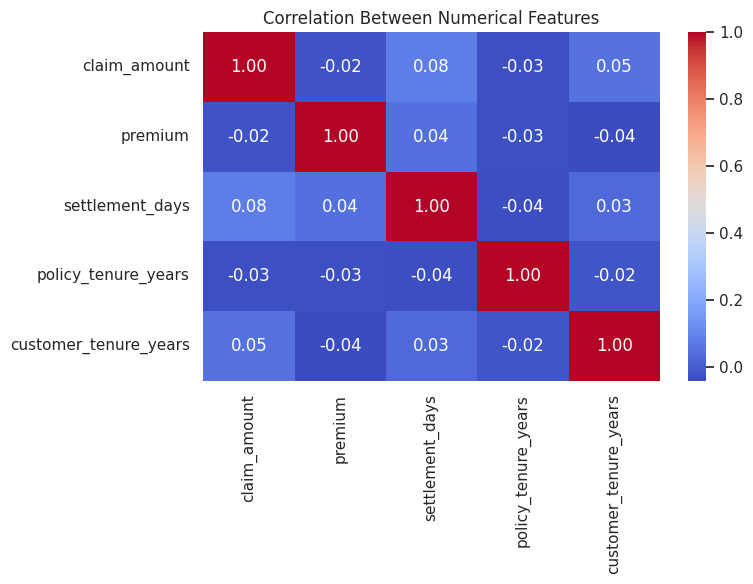

In [18]:

numeric_cols = [
    "claim_amount", "premium", "settlement_days",
    "policy_tenure_years", "customer_tenure_years"
]

plt.figure(figsize=(8, 6))
sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


In [19]:

stage_analysis = df.groupby("process_stage").agg(
    claim_count=("claim_number", "nunique"),
    average_settlement_days=("settlement_days", "mean"),
    median_settlement_days=("settlement_days", "median"),
    average_claim_value=("claim_amount", "mean")
).round(2)

display(
    stage_analysis.sort_values(
        "average_settlement_days", ascending=False
    )
)


,claim_count,average_settlement_days,median_settlement_days,average_claim_value
process_stage,,,,
Document Review,106,33.31,18.0,5575.52
Payment,70,25.27,16.5,5922.24
Investigation,158,24.40,16.5,6593.46
Assessment,118,22.92,17.0,8266.96
Registration,64,18.84,17.0,6871.80
Approval,83,17.30,17.0,10170.47


In [20]:

categorical_columns = [
    "claim_type", "claim_status", "policy_type",
    "region", "incident_type", "severity",
    "process_stage"
]

encoded_df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=False,
    dtype=int
)

print("Original shape:", df.shape)
print("Encoded shape:", encoded_df.shape)
display(encoded_df.head())


Original shape: (599, 27)
Encoded shape: (599, 56)


,claim_number,customer_id,policy_id,incident_id,claim_date,claim_amount,extreme_claim_value,premium,policy_tenure_years,customer_tenure_years,...,severity_High,severity_Low,severity_Medium,severity_Unknown,process_stage_Approval,process_stage_Assessment,process_stage_Document Review,process_stage_Investigation,process_stage_Payment,process_stage_Registration
0,CLM100001,CUST2001,POL3001,INC4001,2025-08-15,3928.53,False,30672.37,4,15,...,1,0,0,0,0,0,0,1,0,0
1,CLM100002,CUST2002,POL3002,INC4002,2025-10-30,3084.27,False,13745.03,9,9,...,1,0,0,0,0,0,0,1,0,0
2,CLM100003,CUST2003,POL3003,INC4003,2025-08-22,3651.67,False,32495.66,7,5,...,0,1,0,0,0,0,0,1,0,0
3,CLM100004,CUST2004,POL3004,INC4004,2025-08-05,9717.59,False,9238.98,15,9,...,1,0,0,0,0,0,0,1,0,0
4,CLM100005,CUST2005,POL3005,INC4005,2025-06-20,2059.95,False,20701.87,12,13,...,1,0,0,0,0,1,0,0,0,0


In [21]:

candidate_features = [
    "claim_amount",
    "premium",
    "policy_tenure_years",
    "customer_tenure_years",
    "settlement_days"
]

correlations = (
    df[candidate_features]
    .corr()["settlement_days"]
    .drop("settlement_days")
    .sort_values(key=abs, ascending=False)
)

print("Correlation with settlement duration:")
display(correlations.to_frame("Correlation"))


Correlation with settlement duration:


,Correlation
claim_amount,0.075563
premium,0.044217
policy_tenure_years,-0.035123
customer_tenure_years,0.027940


In [22]:

import os

output_folder = "/content/insurance_claims_results"
os.makedirs(output_folder, exist_ok=True)

# Save the cleaned combined dataset
df.to_csv(
    f"{output_folder}/insurance_claims_cleaned.csv",
    index=False
)

# Save the encoded dataset
encoded_df.to_csv(
    f"{output_folder}/insurance_claims_encoded.csv",
    index=False
)

# Save analysis summaries
claim_type_summary.to_csv(
    f"{output_folder}/claim_type_summary.csv"
)

region_summary = df.groupby("region").agg(
    claim_count=("claim_number", "nunique"),
    total_claim_value=("claim_amount", "sum"),
    average_claim_value=("claim_amount", "mean")
).round(2)

region_summary.to_csv(
    f"{output_folder}/regional_summary.csv"
)

stage_analysis.to_csv(
    f"{output_folder}/stage_analysis.csv"
)

workload.to_csv(
    f"{output_folder}/investigation_workload.csv"
)

print("All result files saved in:", output_folder)
print(os.listdir(output_folder))


All result files saved in: /content/insurance_claims_results
['regional_summary.csv', 'stage_analysis.csv', 'insurance_claims_encoded.csv', 'claim_type_summary.csv', 'investigation_workload.csv', 'insurance_claims_cleaned.csv']


In [23]:

from google.colab import files

files.download(
    "/content/insurance_claims_results/insurance_claims_cleaned.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>